## Application of MambaVision for Deepfake Detection

This notebook tackles the binary classification problem of distinguishing between real images and those generated by AI (deepfakes). We will use **MambaVision**, a state-of-the-art vision model that combines the strengths of State Space Models (Mamba) and Vision Transformers.

Our process will cover:
1.  **Setup and Installation**: Preparing the environment.
2.  **Data Loading**: Downloading and preparing the deepfake dataset.
3.  **Model Definition**: Loading a pre-trained MambaVision model and tailoring it for our task.
4.  **Training and Validation**: Fine-tuning the model on our dataset.
5.  **Model Evaluation**: Thoroughly assessing the model's performance with various metrics and visualizations.
6.  **Model Explainability**: Using Grad-CAM to understand *why* the model makes its predictions.

### Project Setup
To make it easier to manage datasets, images and models, we create a HOME constant

In [1]:
import os
HOME = os.getcwd()
print(HOME)

/workspace


First, we install the necessary libraries. `mambavision` is the core library for our model, `kagglehub` allows us to easily download the dataset, and `grad-cam` will be used for model explainability.

In [2]:
%pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 38.5 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 23.3.1
    Uninstalling pip-23.3.1:
      Successfully uninstalled pip-23.3.1
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install --no-cache-dir kagglehub huggingface_hub pillow opencv-python matplotlib seaborn numpy pandas pyarrow scikit-learn grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 205.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 330.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 433.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 383.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 118.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 399.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 388.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 456.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 468.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 303.2 MB/s eta 0:00:00
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl si

In [4]:
%pip install --no-cache-dir --no-build-isolation mambavision

  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 243.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 422.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 213.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 479.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 781.7/781.7 kB 503.7 MB/s eta 0:00:00
  Created wheel for mamba-ssm: filename=mamba_ssm-2.2.4-cp310-cp310-linux_x86_64.whl size=342566411 sha256=4edcc2eecd18182f986b6cff6f0d4d69745fb78620b0a17e76dcc9946013d951
  Stored in directory: /tmp/pip-ephem-wheel-cache-q89d5za4/wheels/aa/af/c7/fb77bfcd94bd3e052545033449d8c47dc97222d79c39c5bc67
Successfully built mamba-ssm
  Attempting uninstall: requests
    Found existing installation: requests 2.31.0
    Uninstalling requests-2.31.0:
      Successfully uninstalled requests-2.31.0
  Attempting uninstall: Pillowm━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/13 

In [5]:
import torch

DEVICE = "cpu"

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Current Device:", torch.cuda.current_device())
    print("Device name:", torch.cuda.get_device_name(0))
    DEVICE = torch.device("cuda")
print("DEVICE:", DEVICE)

CUDA available: True
Current Device: 0
Device name: NVIDIA A100 80GB PCIe
DEVICE: cuda


### 1. Download Dataset

We require datasets containing both AI-generated and real images.
<details>
<summary>Here are a list of datasets to use.</summary>


* 1: https://www.kaggle.com/datasets/cashbowman/ai-generated-images-vs-real-images  (975 images, 503MB)
* 2: https://www.kaggle.com/datasets/alessandrasala79/ai-vs-human-generated-dataset (85k images, 11GB)
* 3: https://www.kaggle.com/datasets/tristanzhang32/ai-generated-images-vs-real-images (60k images, 52.41GB)  
* 4: https://huggingface.co/datasets/prithivMLmods/AI-vs-Deepfake-vs-Real  (10k images, 1.96GB)
</details>

<details>
<summary>Here are more datasets, if you want to scale</summary>

* 6: https://www.kaggle.com/datasets/awsaf49/artifact-dataset (2.49M images, 31.58 GB)  
* 7: https://huggingface.co/datasets/delyanboychev/imaginet (800k images, 134GB)  
* 8: https://openxlab.org.cn/datasets/whlzy/FakeImageDataset/tree/main (2M+ images, 667.6GB)  
* 9: https://github.com/GenImage-Dataset/GenImage (2.6M images, unknown file size)  
</details>


In [6]:
# Define the path to store all the dataset files
DOWNLOAD_PATH = os.path.join(HOME, "downloads")
DATASET_PATH = os.path.join(HOME, "dataset")
VISUALIZATION_PATH = os.path.join(HOME, "visualizations")
MODEL_SAVE_PATH = os.path.join(HOME, "models")

# Create the directories if they don't exist
os.makedirs(DOWNLOAD_PATH, exist_ok=True)
os.makedirs(DATASET_PATH, exist_ok=True)
os.makedirs(VISUALIZATION_PATH, exist_ok=True)
os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

print(f"DOWNLOAD_PATH:{DOWNLOAD_PATH} \nDATASET_PATH:{DATASET_PATH} \nVISUALIZATION_PATH: {VISUALIZATION_PATH} \nMODEL_SAVE_PATH: {MODEL_SAVE_PATH}")

DOWNLOAD_PATH:/workspace/downloads 
DATASET_PATH:/workspace/dataset 
VISUALIZATION_PATH: /workspace/visualizations 
MODEL_SAVE_PATH: /workspace/models


In [7]:
import os
# Set environment variable before importing or using kagglehub
os.environ['KAGGLEHUB_CACHE'] = DOWNLOAD_PATH

import kagglehub

# Download the datasets from Kaggle
download_paths = [] 
dataset_urls = [
    'cashbowman/ai-generated-images-vs-real-images',
    'alessandrasala79/ai-vs-human-generated-dataset',
    'tristanzhang32/ai-generated-images-vs-real-images'
]

for url in dataset_urls:
    download_path = kagglehub.dataset_download(url)
    download_paths.append(download_path)
    
print(f'kaggle Datasets downloaded to: {download_paths}')

100%|██████████| 476M/476M [00:04<00:00, 109MB/s]  

Extracting files...


100%|██████████| 9.76G/9.76G [01:50<00:00, 95.2MB/s]

Extracting files...


100%|██████████| 48.4G/48.4G [07:07<00:00, 122MB/s]   

Extracting files...


kaggle Datasets downloaded to: ['/workspace/downloads/datasets/cashbowman/ai-generated-images-vs-real-images/versions/1', '/workspace/downloads/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4', '/workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2']


In [8]:
from huggingface_hub import snapshot_download
import os

# Define the main download directory
DOWNLOAD_PATH = "/workspace/downloads"
os.makedirs(DOWNLOAD_PATH, exist_ok=True)

# We now download each dataset into a unique subfolder to keep them separate.

download_paths = []
dataset_urls = [
    'prithivMLmods/AI-vs-Deepfake-vs-Real'
    # 'Hemg/AI-Generated-vs-Real-Images-Datasets'
]

print("Starting dataset downloads...")
for url in dataset_urls:
    # Create a specific path for each dataset inside DOWNLOAD_PATH
    repo_local_path = os.path.join(DOWNLOAD_PATH, url)
    
    print(f"Downloading '{url}' to '{repo_local_path}'...")
    
    # Use the new path as the local_dir
    download_path = snapshot_download(
        repo_id=url,
        repo_type="dataset",
        local_dir=repo_local_path
    )
    download_paths.append(download_path)
    
print(f'\nAll datasets downloaded to their respective folders inside {DOWNLOAD_PATH}')
print('Downloaded paths:', download_paths)

Starting dataset downloads...


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

.gitattributes:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

0002.parquet:   0%|          | 0.00/521M [00:00<?, ?B/s]

0003.parquet:   0%|          | 0.00/422M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

0001.parquet:   0%|          | 0.00/506M [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/508M [00:00<?, ?B/s]


All datasets downloaded to their respective folders inside /workspace/downloads
Downloaded paths: ['/workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real']


Verify the structure of the dataset files

In [9]:
for root, dirs, files in os.walk(DOWNLOAD_PATH):
    print(f'Found folder: {root} with {len(files)} files')

Found folder: /workspace/downloads with 0 files
Found folder: /workspace/downloads/prithivMLmods with 0 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real with 6 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/.cache with 0 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/.cache/huggingface with 1 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/.cache/huggingface/download with 12 files
Found folder: /workspace/downloads/datasets with 0 files
Found folder: /workspace/downloads/datasets/tristanzhang32 with 0 files
Found folder: /workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images with 1 files
Found folder: /workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions with 0 files
Found folder: /workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2 with 0 files
Found folder: /workspace/

### 2. Organize Dataset

Organize all the datasets by doing these:
1.   Move all the images from their existing folders into 1 of 2 new folders (depends on their label).
2.   Some datasets have the image labels in .csv files, read the csv files and sort the images into folders based on their labels

In [10]:
print("Starting dataset organization...")

Starting dataset organization...


The huggingface datasets have .parquet files, these files contain images and labels.

In [ ]:
# View / Unpack '.parquet' files into label-named folders

import os
import pandas as pd
from PIL import Image
import io
from tqdm.notebook import tqdm

# Find all .parquet files first, before any processing.
print("Scanning for all .parquet files...")
parquet_files = []
for root, _, files in os.walk(DOWNLOAD_PATH):
    for file in files:
        if file.endswith(".parquet"):
            parquet_files.append(os.path.join(root, file))

if parquet_files:
    print(f"Found {len(parquet_files)} .parquet file(s). Starting unpacking process...")

    image_counters = {}
    new_folders_created = set() 

    for p_file in tqdm(parquet_files, desc="Processing All Parquet Files"):
        try:
            df = pd.read_parquet(p_file)

            # Print the header of each p_file
            print(f"--- Data structure for {p_file} ---")
            print(df.head())
            print("--------------------------------------------")
            
            continue  # COMMENT THIS LINE TO extract more images and labels from the parquet files
        
            # Basic validation for the required columns
            if 'image' not in df.columns or 'label' not in df.columns:
                print(f"Skipping {p_file}: Lacks 'image' or 'label' columns. Columns found: {df.columns}")
                continue
           
            for _, row in tqdm(df.iterrows(), total=len(df), desc=f"Unpacking {os.path.basename(p_file)}", leave=False):
                label_int = row['label']
                label_str = str(label_int)  # Folder name will be '0', '1', '2', etc.
                image_bytes = row['image']['bytes']

                # Destination directory is relative to the parquet file's location
                dest_dir = os.path.join(os.path.dirname(p_file), label_str)
                os.makedirs(dest_dir, exist_ok=True)
                new_folders_created.add(dest_dir) # Store full path for clarity

                image_counters.setdefault(label_str, 0)

                try:
                    image = Image.open(io.BytesIO(image_bytes))
                    if image.mode != 'RGB':
                        image = image.convert('RGB')

                    image_counters[label_str] += 1
                    # Use a more unique name to avoid potential collisions if we re-run
                    filename = f"label_{label_str}_img_{image_counters[label_str]:06d}.jpg"
                    save_path = os.path.join(dest_dir, filename)
                    image.save(save_path, 'JPEG')
                except Exception as img_e:
                    print(f"Warning: Skipping a possibly corrupt image in {p_file}. Error: {img_e}") # Skip corrupted or unreadable images
            
            # Delete the parquet file after successful processing to save space
            os.remove(p_file)
            print(f"Successfully unpacked and deleted {p_file}")

        except Exception as e:
            print(f"Error processing {p_file}: {e}")

    print("\n--- Parquet Processing Complete ---")
    if new_folders_created:
        print(f"Images were unpacked into subfolders within these directories: {sorted(list(new_folders_created))}")
    
    print("\nTotal Images Unpacked per Label:")
    for label, count in sorted(image_counters.items()):
        print(f"  - Unpacked {count} images to folders named '{label}'")
        
print("Finished Processing all Parquet files")

Scanning for all .parquet files...
Found 4 .parquet file(s). Starting unpacking process...


Processing All Parquet Files:   0%|          | 0/4 [00:00<?, ?it/s]

--- Data structure for /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/0003.parquet ---
                                               image  label
0  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
2  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
3  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
4  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
--------------------------------------------
--- Data structure for /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/0002.parquet ---
                                               image  label
0  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
2  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
3  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
4  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...      1
---------------------------------------

In [ ]:
# 1. move all the images from their folders into categorized directories

import os
import shutil
from pathlib import Path

# Configuration, you may need to verify the meaning of each label from each dataset's documentation or by manually viewing it.
categories = {
    'real': {'key_folders': ['realart', 'real'], 'counter': 0},
    'fake': {'key_folders': ['aiartdata', 'ai', 'fake'], 'counter': 0}
}

# Create destination directories
dest_paths = {cat: Path(DATASET_PATH) / cat for cat in categories}
for path in dest_paths.values():
    path.mkdir(exist_ok=True)

print(f"Destination folders ready: {', '.join(map(str, dest_paths.values()))}")

# Process files
for root, dirs, files in os.walk(DOWNLOAD_PATH):
    if not files or root in map(str, dest_paths.values()):
        continue
    current_dir = Path(root).name.lower()
    
    # Find matching category
    category = next((cat for cat, config in categories.items() if current_dir in config['key_folders']), None)
    if category:
        print(f"Processing '{root}'...")
        
        for file in files:
            categories[category]['counter'] += 1
            src = Path(root) / file
            ext = src.suffix
            new_name = f"{category}_{categories[category]['counter']:06d}{ext}"
            dst = dest_paths[category] / new_name
            
            shutil.move(str(src), str(dst))
        
        print(f"  -> Moved {len(files)} files to '{category}' directory.")

# Summary
print("Dataset organization almost complete ...")
for cat, config in categories.items():
    print(f"Current {cat.upper()} images moved: {config['counter']}")

Destination folders ready: /workspace/dataset/real, /workspace/dataset/fake
Processing '/workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2/train/real'...
  -> Moved 24000 files to 'real' directory.
Processing '/workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2/train/fake'...
  -> Moved 24000 files to 'fake' directory.
Processing '/workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2/test/real'...
  -> Moved 6000 files to 'real' directory.
Processing '/workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2/test/fake'...
  -> Moved 6000 files to 'fake' directory.
Processing '/workspace/downloads/datasets/cashbowman/ai-generated-images-vs-real-images/versions/1/RealArt/RealArt'...
  -> Moved 436 files to 'real' directory.
Processing '/workspace/downloads/datasets/cashbowman/ai-generated-images-vs-real-images/versions/1/AiArtData/AiArtData'

In [ ]:
# 2. read csv files and sort image files based on their labels

import shutil
from pathlib import Path
import pandas as pd

print("Continue dataset organization...")

# Find train_data folder
train_data_dirs = list(Path(DOWNLOAD_PATH).rglob('train_data'))
if not train_data_dirs:
    raise FileNotFoundError("Could not find 'train_data' folder in the specified DOWNLOAD_PATH.")

train_data_path = train_data_dirs[0]
csv_path = train_data_path.parent / 'train.csv'
label_category = {0: 'fake', 1: 'real'} # In the train.csv, 0 means fake and 1 is real

# Load CSV
df = pd.read_csv(csv_path)
print(f"Loaded {len(df)} records from CSV")

# Create directories and counters
dest_paths = {cat: Path(DATASET_PATH) / cat for cat in label_category.values()}
counters = {cat: 0 for cat in label_category.values()}
for path in dest_paths.values():
    path.mkdir(parents=True, exist_ok=True)
print(f"Destination directories: {list(dest_paths.keys())}")

# Process files
for _, row in df.iterrows():
    category = label_category.get(row['label'])
    if not category:
        print(f"Warning: Unknown label {row['label']}")
        continue

    src_path = train_data_path.parent / row['file_name']
    if not src_path.exists():
        print(f"Warning: Missing file {src_path}")
        continue

    counters[category] += 1
    new_name = f"{category}_{counters[category]:06d}{src_path.suffix}"
    dest_path = dest_paths[category] / new_name
    shutil.move(str(src_path), str(dest_path))

# Summary
print("\nOrganization complete:")
total_moved = 0
for category, count in counters.items():
    print(f"{category.upper()}: {count} images")
    total_moved += count
print(f"Total alessandrasala79 dataset images moved: {total_moved}")


Continue dataset organization...
Loaded 79950 records from CSV
Destination directories: ['fake', 'real']

Organization complete:
FAKE: 39975 images
REAL: 39975 images
Total alessandrasala79 dataset images moved: 79950


All the datasets have now been organized.

In [ ]:
for root, dirs, files in os.walk(DOWNLOAD_PATH):
    print(f'Found folder: {root} with {len(files)} files')

Found folder: /workspace/downloads with 0 files
Found folder: /workspace/downloads/prithivMLmods with 0 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real with 6 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/.cache with 0 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/.cache/huggingface with 1 files
Found folder: /workspace/downloads/prithivMLmods/AI-vs-Deepfake-vs-Real/.cache/huggingface/download with 12 files
Found folder: /workspace/downloads/datasets with 0 files
Found folder: /workspace/downloads/datasets/tristanzhang32 with 0 files
Found folder: /workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images with 1 files
Found folder: /workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions with 0 files
Found folder: /workspace/downloads/datasets/tristanzhang32/ai-generated-images-vs-real-images/versions/2 with 0 files
Found folder: /workspace/

In [ ]:
# Count the total number of images in the dataset

for root, dirs, files in os.walk(DATASET_PATH):
    print(f'Found folder: {root} with {len(files)} files')
    
for root, dirs, files in os.walk(DATASET_PATH):
    print(f"Total {str(os.path.basename(root)).upper()} images : {len(files)}")

Found folder: /workspace/dataset with 0 files
Found folder: /workspace/dataset/fake with 50818 files
Found folder: /workspace/dataset/real with 40033 files
Total DATASET images : 0
Total FAKE images : 50818
Total REAL images : 40033


Display a grid of random image samples from across the dataset for both real and ai images.

In [ ]:
import os
import math
import random

import cv2
import matplotlib.pyplot as plt

# Randomly selects images from dataset, creates a grid image, and saves it.
filepaths = []
dataset_grid_image = ""
no_of_images=20

# Use os.walk to find all image files in DATASET_PATH and subdirectories
for root, _, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            filepaths.append(os.path.join(root, file))
            
if filepaths:
    num_to_sample = min(no_of_images, len(filepaths))
    images_to_visualize = random.sample(filepaths, num_to_sample)
    images = []
    for image_path in images_to_visualize:
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Could not read image at {image_path}. Skipping.")
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        title = f"{os.path.basename(os.path.dirname(image_path))}/{os.path.basename(image_path)}"
        images.append((image, title))

    
    if images:    
        # Determine grid size (e.g., for 5 images: 3x2 grid)
        grid_cols = math.ceil(math.sqrt(len(images)))
        grid_rows = math.ceil(len(images) / grid_cols)
        fig, axs = plt.subplots(grid_rows, grid_cols, figsize=(grid_cols * 4, grid_rows * 4))
        axs = axs.flatten()
        for ax, (img, title) in zip(axs, images):
            ax.imshow(img)
            ax.set_title(title, fontsize=10)
            ax.axis("off")
        # Hide any unused subplots
        for ax in axs[len(images):]:
            ax.axis("off")
        plt.tight_layout()
        dataset_grid_image = os.path.join(VISUALIZATION_PATH, f'dataset_visualization_grid.png')
        plt.savefig(dataset_grid_image)
        plt.close(fig)
        print(dataset_grid_image) # it is an image path string

/workspace/visualizations/dataset_visualization_grid.png


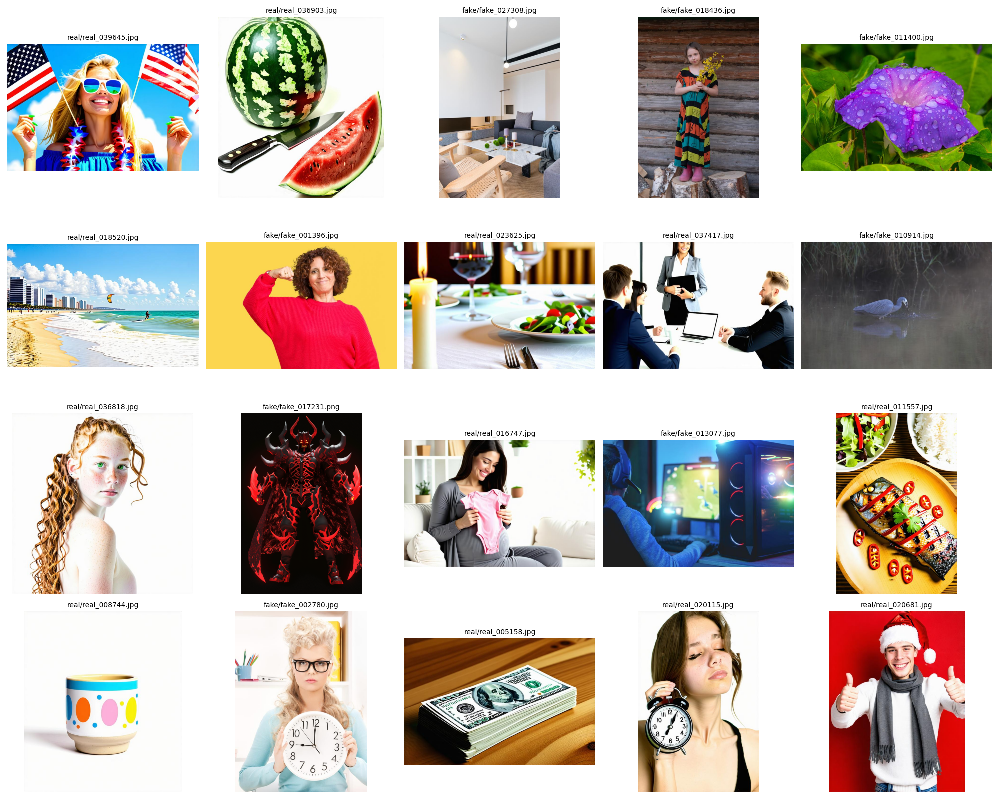

In [ ]:
from IPython.display import Image as IPyImage

# Display the image
IPyImage(filename=dataset_grid_image, width=600)

### 3. Dataset Transformation and Loading

A Transformation is any operation that modifies an image. 
An Augmentation is a specific type of transformation randomly applied to the training data to improve model generalization.

Here, we perform standard transformations on the dataset images (resize to 224x224 and, normalize).
Also, augmentations like color jitter, horizontal flip, etc. are applied randomly to each image in each epoch, creating a constantly changing stream of training data.

Custom PyTorch Dataset class for loading real and fake images from path.

In [ ]:
from PIL import Image
from torch.utils.data import Dataset
import warnings 

# Suppress just this specific UserWarning from PIL
warnings.filterwarnings(
    "ignore",
    message="Palette images with Transparency expressed in bytes should be converted to RGBA images",
    category=UserWarning,
    module="PIL.Image"
)

class MyDataset(Dataset):
    def __init__(self, image_paths, image_labels, transform):
        self.image_paths = image_paths
        self.image_labels = image_labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        try:
            image = Image.open(img_path).convert("RGB")
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
        label = self.image_labels[idx] # And here
        if self.transform:
            image = self.transform(image)
        return image, label
    
print(f"MyDataset: {MyDataset}")

MyDataset: <class '__main__.MyDataset'>


Dataset Transformation (Augmentation) and Dataset Loading

In [27]:
import pandas as pd
import os
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split

def create_splits(dataset_path, train_size=0.7, val_size=0.15, test_size=0.15, random_state=42):
    """Creates stratified train, validation, and test splits."""
    filepaths = []
    labels = []
    supported = ['.jpg', '.png', '.jpeg']
    
    # Get class names from subdirectories
    classes = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
    classes.sort()
    class_to_idx = {name: i for i, name in enumerate(classes)}

    # Collect all file paths and their corresponding labels
    for klass in classes:
        class_dir = os.path.join(dataset_path, klass)
        for file in os.listdir(class_dir):
            if file.lower().endswith(tuple(supported)):
                filepaths.append(os.path.join(class_dir, file))
                labels.append(klass)

    df = pd.DataFrame({'filepath': filepaths, 'label': labels})

    # Create initial training split (70%)
    train_df, temp_df = train_test_split(
        df, train_size=train_size, shuffle=True, stratify=df['label'], random_state=random_state
    )

    # Split the remaining data (30%) into validation (15%) and test (15%)
    # The new test_size is 0.5 because we are splitting the 30% into two 15% chunks.
    val_df, test_df = train_test_split(
        temp_df, test_size=0.5, shuffle=True, stratify=temp_df['label'], random_state=random_state
    )
    
    # Convert labels to indices
    train_labels = [class_to_idx[lbl] for lbl in train_df['label']]
    val_labels = [class_to_idx[lbl] for lbl in val_df['label']]
    test_labels = [class_to_idx[lbl] for lbl in test_df['label']]

    print(f"Training set size: {len(train_df)}")
    print(f"Validation set size: {len(val_df)}")
    print(f"Test set size: {len(test_df)}")
    print(f"Class mapping: {class_to_idx}")

    return (
        train_df['filepath'].tolist(), train_labels,
        val_df['filepath'].tolist(), val_labels,
        test_df['filepath'].tolist(), test_labels,
        class_to_idx
    )

# Create the splits
train_paths, train_labels, val_paths, val_labels, test_paths, test_labels, class_indices = create_splits(DATASET_PATH)
input_size = 224

# Define transformations
# Using standard ImageNet stats is generally a better starting point for pretrained models
imagenet_mean, imagenet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.RandomResizedCrop(size=(input_size, input_size), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1), ratio=(0.3, 3.3)),
])

val_test_transform = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

# Create Dataset objects
train_dataset = MyDataset(train_paths, train_labels, train_transform)
val_dataset = MyDataset(val_paths, val_labels, val_test_transform)
test_dataset = MyDataset(test_paths, test_labels, val_test_transform) # Use non-augmented transform

# Create DataLoader objects
BATCH_SIZE = 256 # Increased batch size for better GPU utilization
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=16, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=16, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=16, pin_memory=True)

Training set size: 63592
Validation set size: 13627
Test set size: 13627
Class mapping: {'fake': 0, 'real': 1}


In [28]:
# Builds and saves visualizations of augmented images in grid images, using the dataset's transform pipeline.
import os
import math
import random

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms

# Helper function to denormalize and prepare an image tensor for plotting
def denormalize_image(tensor_image):
    """Converts a normalized tensor image to a plottable numpy array."""
    # Assumes normalization with mean=0.5, std=0.5. Reverses by (tensor * std) + mean
    image_np = tensor_image.permute(1, 2, 0).cpu().numpy()
    image_np = image_np * 0.5 + 0.5
    image_np = np.clip(image_np, 0, 1)  # Clip values to [0, 1] for valid display
    return image_np

dataset = train_dataset #The dataset object with the attached transform.
num_images=4 #number of original images to augment and display.
augmentations_per_image=8 #number of augmented versions per original image.

num_images_to_show = min(num_images, len(dataset))
random_indices = random.sample(range(len(dataset)), num_images_to_show)
output_files = []

# Create a simple resize transform for displaying the original image consistently.
# It expects a PIL Image.
resize_for_display = transforms.Resize((input_size, input_size))

for i, image_idx in enumerate(random_indices):
    image_path = dataset.image_paths[image_idx]
    # Load image with OpenCV (as in original), then convert to RGB and finally to a PIL Image,
    # as torchvision transforms expect PIL Images.
    original_image_bgr = cv2.imread(image_path)
    original_image_rgb = cv2.cvtColor(original_image_bgr, cv2.COLOR_BGR2RGB)
    original_pil = Image.fromarray(original_image_rgb)

    # Create a grid for one original + multiple augmented images
    grid_size = math.ceil(math.sqrt(augmentations_per_image + 1))
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(grid_size * 3, grid_size * 3))
    axes = axes.flatten()

    # Display the original image (resized for fair comparison using torchvision)
    resized_original = resize_for_display(original_pil)
    axes[0].imshow(resized_original)
    axes[0].set_title("Original")
    axes[0].axis("off")

    # Generate and display augmented images
    for j in range(augmentations_per_image):
        # The dataset's transform pipeline now expects a PIL Image and returns a Tensor.
        augmented_tensor = dataset.transform(original_pil)
        augmented_image_np = denormalize_image(augmented_tensor)
        axes[j + 1].imshow(augmented_image_np)
        axes[j + 1].set_title(f"Augmented {j+1}")
        axes[j + 1].axis("off")

    # Hide any unused subplots
    for k in range(augmentations_per_image + 1, len(axes)):
        axes[k].axis("off")

    plt.tight_layout()
    output_path = os.path.join(VISUALIZATION_PATH, f'augmentation_grid_{i}.png')
    plt.savefig(output_path)
    plt.close(fig)
    output_files.append(output_path)

print(f"Saved {len(output_files)} augmentation visualizations to '{VISUALIZATION_PATH}'")

Saved 4 augmentation visualizations to '/workspace/visualizations'


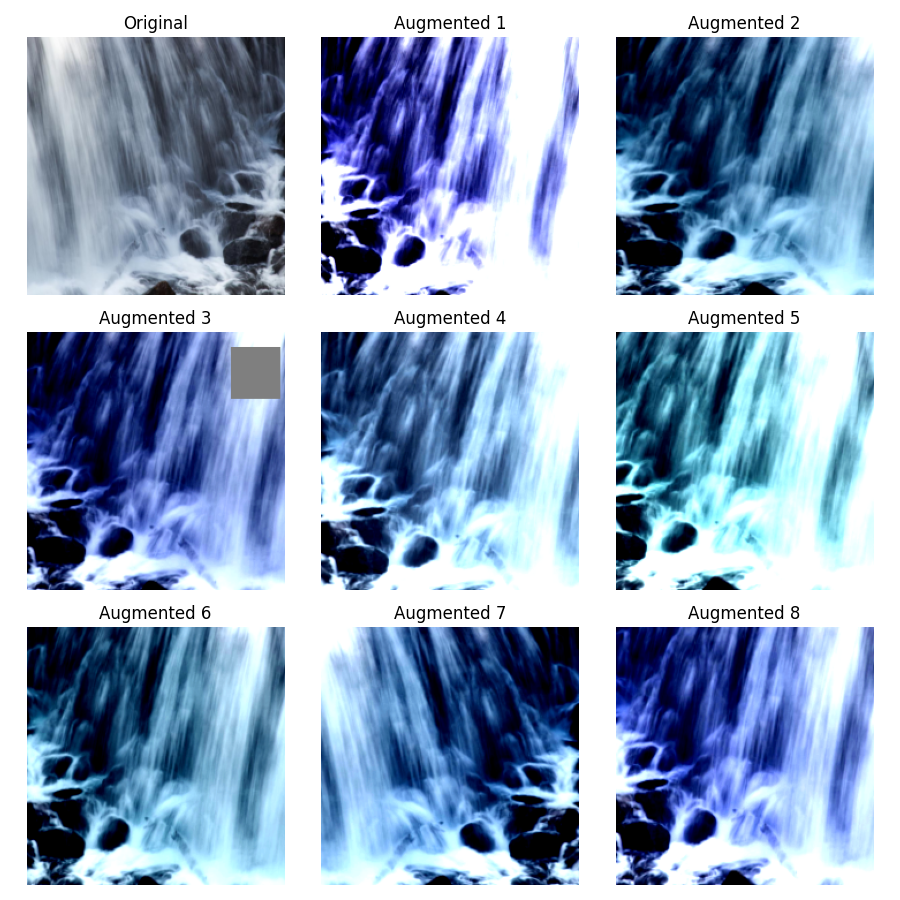

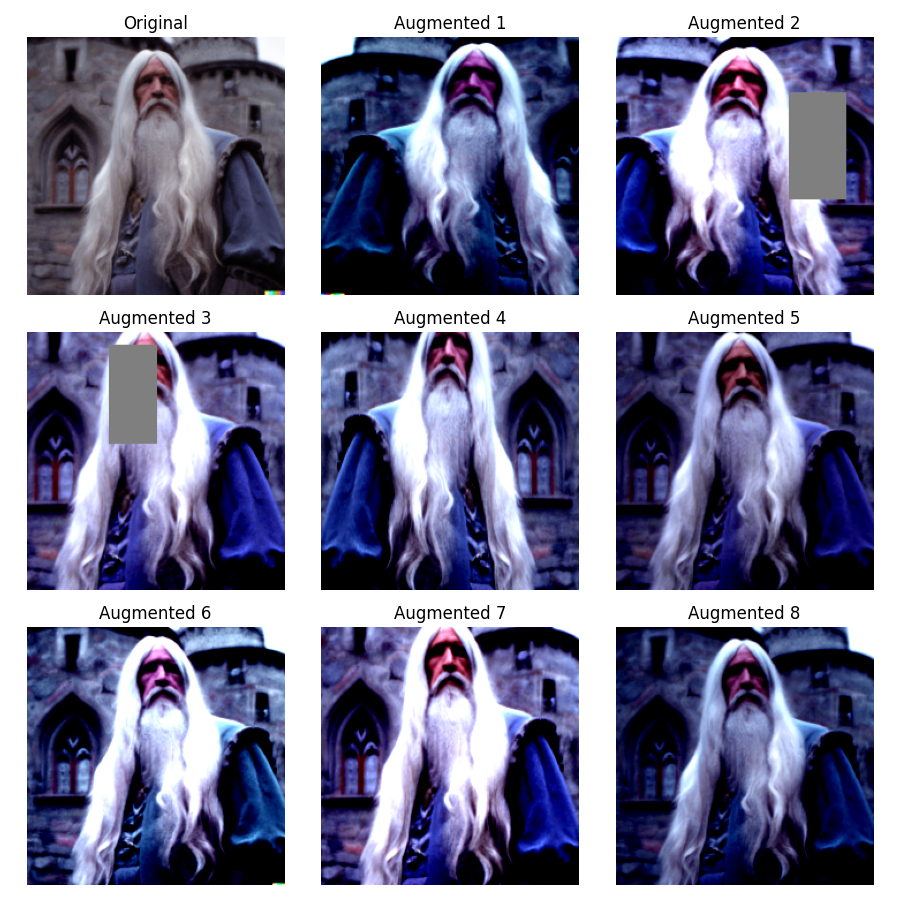

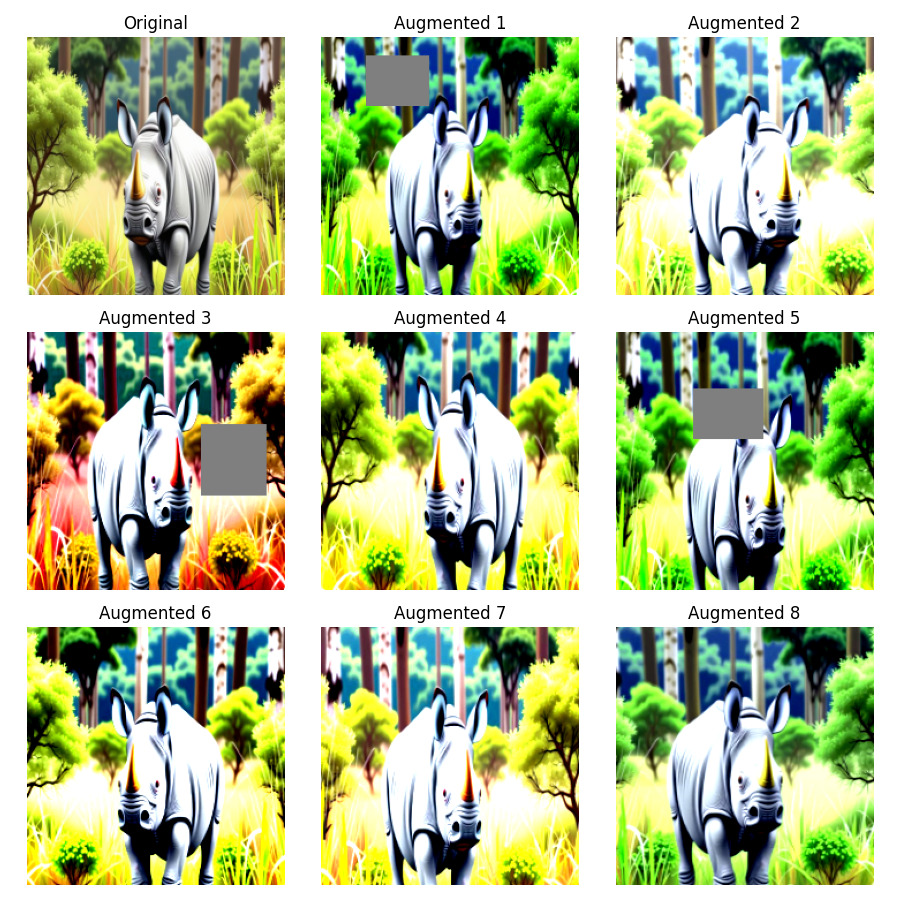

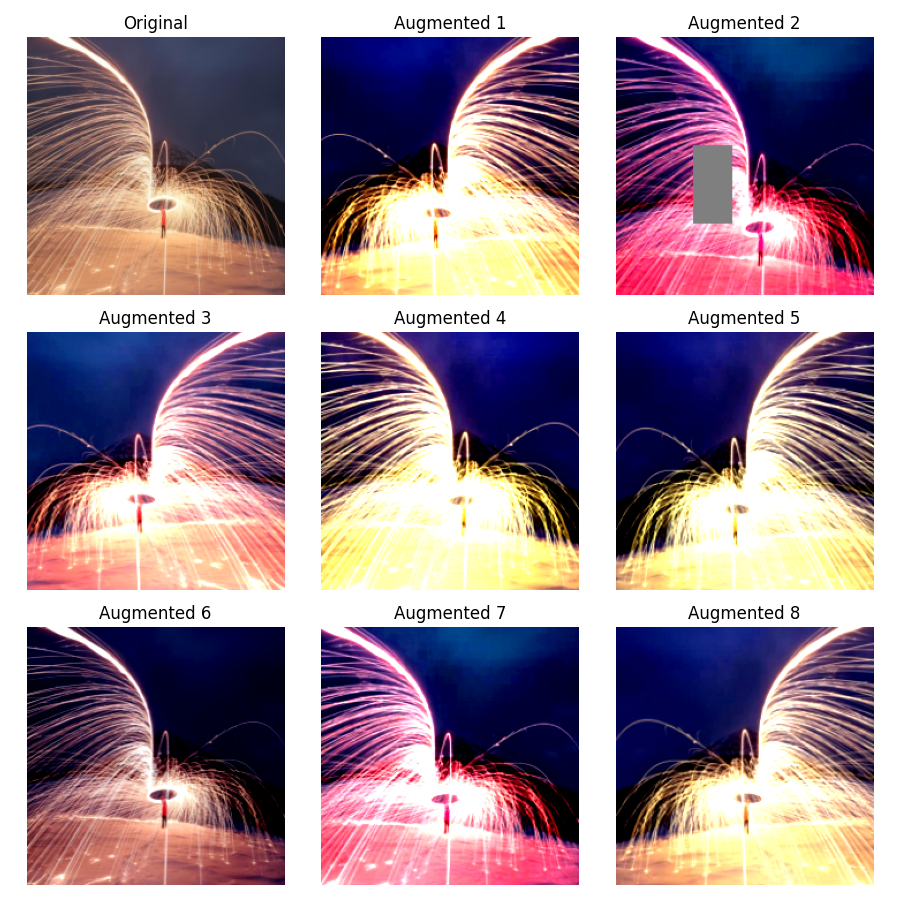

In [29]:
from IPython.display import Image as IPyImage, display

# Display the images
for image_path in output_files:
    display(IPyImage(filename=image_path, width=600))

### 4. MambaVision Model

MambaVision is a hybrid deep learning architecture that combines the efficiency of the State Space Model (SSM), specifically Mamba with the global context of the Vision Transformer (ViT). ViTs can capture the global relationships between different parts of an image.

We use the `mambavision` library to create a pre-trained `mamba_vision_T` (Tiny) model. The pre-trained weights are loaded from a public checkpoint.

MambaVision Model variants are: `'mamba_vision_T'`, `'mamba_vision_T2'`, `'mamba_vision_S'`, `'mamba_vision_B'`, `'mamba_vision_L'`, `'mamba_vision_L2'` and they correspond to Tiny, Small, Base, Large, and larger variants respectively.

Download the Model and make a prediction

In [30]:
from mambavision import create_model
# Create the MambaVision model
# We use a pre-trained Large version for finetuning.
model = create_model('mamba_vision_L2', pretrained=True)

print(f"Model: {str(model)[:300]} \nClass: {type(model)} \nTrainable parameters : {sum(p.numel() for p in model.parameters() if p.requires_grad)} \nLayer weights: {list(model.state_dict().keys())}")

Model: MambaVision(
  (patch_embed): PatchEmbed(
    (proj): Identity()
    (conv_down): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=0.0001, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3 
Class: <class 'mambavision.models.mamba_vision.MambaVision'> 
Trainable parameters : 241554824 
Layer weights: ['patch_embed.conv_down.0.weight', 'patch_embed.conv_down.1.weight', 'patch_embed.conv_down.1.bias', 'patch_embed.conv_down.1.running_mean', 'patch_embed.conv_down.1.running_var', 'patch_embed.conv_down.1.num_batches_tracked', 'patch_embed.conv_down.3.weight', 'patch_embed.conv_down.4.weight', 'patch_embed.conv_down.4.bias', 'patch_embed.conv_down.4.running_mean', 'patch_embed.conv_down.4.running_var', 'patch_embed.conv_down.4.num_batches_tracked', 'levels.0.blocks.0.conv1.weight', 'levels.0.blocks.0.conv1.bias', 'levels.0.blocks.0.norm1.weight', 'levels.0.blocks.0.norm1.bi

Since our task is binary classification (Real vs. Fake), we replace the model's final layer (`head`) with a new `nn.Linear` layer that has a single output neuron.

In [31]:
import torch.nn as nn

# Modify the final classification layer for our binary task (1 output neuron)
model.head = nn.Linear(in_features=model.head.in_features, out_features=1)

# Move the model to the selected DEVICE (GPU or CPU)
model.to(DEVICE)

# Define the loss function, optimizer, and learning rate scheduler
criterion = nn.BCEWithLogitsLoss() # Best for binary classification with a single logit output
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.85) 

print(f"Head: {model.head} \nDevice: {next(model.parameters()).device} \nCriterion: {criterion} \nOptimizer: {optimizer} \nScheduler: {scheduler}")

Head: Linear(in_features=1568, out_features=1, bias=True) 
Device: cuda:0 
Criterion: BCEWithLogitsLoss() 
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0001
    lr: 0.0001
    maximize: False
    weight_decay: 0.0005
) 
Scheduler: <torch.optim.lr_scheduler.ExponentialLR object at 0x7fe1681aa920>


### 5. Training and Validation

Here we define the core training and validation functions. The `train_one_epoch` function processes the training data, computes loss, and updates the model weights. The `validate` function evaluates the model on the validation set without updating weights.

In [ ]:
from tqdm.notebook import tqdm

def get_accuracy(preds, labels):
    """Calculates accuracy for binary classification with logits."""
    predicted_labels = torch.sigmoid(preds.flatten()) > 0.5
    return torch.sum(predicted_labels == labels.bool()) / labels.numel()

def train_one_epoch(model, loader, criterion, optimizer, DEVICE):
    model.train()
    running_loss = 0.0
    running_acc = 0.0
    
    pbar = tqdm(loader, desc="Training", leave=False)
    for inputs, labels in pbar:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = criterion(outputs, labels.unsqueeze(-1).float()) # Ensure labels are float for loss
        
        loss.backward()
        optimizer.step()
        
        acc = get_accuracy(outputs, labels)
        running_loss += loss.item() * inputs.size(0)
        running_acc += acc.item() * inputs.size(0)
        
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{acc.item():.4f}")
        
    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = running_acc / len(loader.dataset)
    return epoch_loss, epoch_acc

def validate(model, loader, criterion, DEVICE):
    model.eval()
    running_loss = 0.0
    running_acc = 0.0
    
    with torch.no_grad():
        pbar = tqdm(loader, desc="Validating", leave=False)
        for inputs, labels in pbar:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels.unsqueeze(-1).float())
            
            acc = get_accuracy(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            running_acc += acc.item() * inputs.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{acc.item():.4f}")
            
    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = running_acc / len(loader.dataset)
    return epoch_loss, epoch_acc

print("Training Functions Loaded")

Training Functions Loaded


Now we run the main training loop. We'll train for a few epochs, track the loss and accuracy, and save the model with the highest validation accuracy.

In [33]:
# Cell for the main training loop with Early Stopping and CSV Logging

import numpy as np
import pandas as pd

# --- Setup for Logging and Saving ---
history_csv_path = os.path.join(VISUALIZATION_PATH, "training_history.csv")

# --- Hyperparameters for Early Stopping ---
num_epochs = 300
patience = 5
min_delta = 0.001

# --- Initialization ---
best_val_loss = np.inf
patience_counter = 0
best_model_path = ""

# Clear any previous history file at the start of a new training run
if os.path.exists(history_csv_path):
    os.remove(history_csv_path)

# --- Main Training Loop ---
for epoch in range(num_epochs):
    print(f"\n--- Epoch {epoch+1}/{num_epochs} ---")

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)

    scheduler.step()

    print(f"Epoch {epoch+1} Summary:")
    print(f"\tTrain Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"\tVal Loss:   {val_loss:.4f}, Val Acc:   {val_acc:.4f}")

    # --- Save history to CSV after each epoch ---
    epoch_data = {
        'epoch': [epoch + 1],
        'train_loss': [train_loss],
        'train_acc': [train_acc],
        'val_loss': [val_loss],
        'val_acc': [val_acc]
    }
    epoch_df = pd.DataFrame(epoch_data)

    # If the file doesn't exist, write the header. Otherwise, append without the header.
    write_header = not os.path.exists(history_csv_path)
    epoch_df.to_csv(history_csv_path, mode='a', header=write_header, index=False)
    
    # --- Early Stopping Logic ---
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        patience_counter = 0
        best_model_path = os.path.join(MODEL_SAVE_PATH, f"best_model_epoch_{epoch+1}_valloss_{val_loss:.4f}.pt")
        torch.save(model.state_dict(), best_model_path)
        print(f"Validation loss improved to {val_loss:.4f}. Saving model to {best_model_path}")
    else:
        patience_counter += 1
        print(f"No improvement in validation loss for {patience_counter} epoch(s). Patience is {patience}.")

    if patience_counter >= patience:
        print(f"\nEarly stopping triggered after {patience} epochs with no improvement.")
        break

print("\nTraining complete.")
print(f"Training history saved to: {history_csv_path}")
if best_model_path:
    print(f"Best model saved at: {best_model_path}")
else:
    print("Training finished, but no best model was saved.")


--- Epoch 1/300 ---


Training:   0%|          | 0/249 [00:00<?, ?it/s]

Validating:   0%|          | 0/54 [00:00<?, ?it/s]

Epoch 1 Summary:
	Train Loss: 0.1090, Train Acc: 0.9580
	Val Loss:   0.0540, Val Acc:   0.9783
Validation loss improved to 0.0540. Saving model to /workspace/models/best_model_epoch_1_valloss_0.0540.pt

--- Epoch 2/300 ---


Training:   0%|          | 0/249 [00:00<?, ?it/s]

...

Training:   0%|          | 0/249 [00:00<?, ?it/s]

Validating:   0%|          | 0/54 [00:00<?, ?it/s]

Epoch 15 Summary:
	Train Loss: 0.0089, Train Acc: 0.9975
	Val Loss:   0.0123, Val Acc:   0.9971
Validation loss improved to 0.0123. Saving model to /workspace/models/best_model_epoch_15_valloss_0.0123.pt

--- Epoch 16/300 ---


Training:   0%|          | 0/249 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [34]:
print(f"\nEarly stopping triggered after {patience} epochs with no improvement.")
print("\nTraining complete.")
print(f"Training history saved to: {history_csv_path}")
if best_model_path:
    print(f"Best model saved at: {best_model_path}")
else:
    print("Training finished, but no best model was saved.")


Early stopping triggered after 5 epochs with no improvement.

Training complete.
Training history saved to: /workspace/visualizations/training_history.csv
Best model saved at: /workspace/models/best_model_epoch_15_valloss_0.0123.pt


#### Training History Visualization

Lastly, let's visualize the training and validation loss and accuracy over epochs to check for things like overfitting.

Loaded training history from /workspace/visualizations/training_history.csv


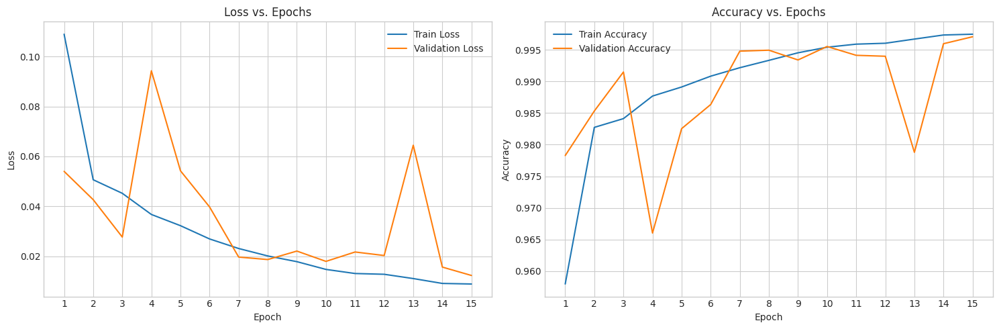

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define the path to the history file
history_csv_path = os.path.join(VISUALIZATION_PATH, "training_history.csv")

if not os.path.exists(history_csv_path):
    print("Training history file not found. Please run the training loop first.")
else:
    # Load the history from the CSV file
    history_df = pd.read_csv(history_csv_path)
    print(f"Loaded training history from {history_csv_path}")

    # Create the plots
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Plot Loss
    ax1.plot(history_df['epoch'], history_df['train_loss'], label='Train Loss')
    ax1.plot(history_df['epoch'], history_df['val_loss'], label='Validation Loss')
    ax1.set_title('Loss vs. Epochs')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.set_xticks(history_df['epoch']) # Ensure integer ticks for epochs

    # Plot Accuracy
    ax2.plot(history_df['epoch'], history_df['train_acc'], label='Train Accuracy')
    ax2.plot(history_df['epoch'], history_df['val_acc'], label='Validation Accuracy')
    ax2.set_title('Accuracy vs. Epochs')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.set_xticks(history_df['epoch']) # Ensure integer ticks for epochs

    plt.tight_layout()
    plt.show()

### 6. Model Evaluation

With training complete, we now perform a comprehensive evaluation of our best model. 

Now we load our best model and run it on the entire validation set to get its predictions. We then compute a wide range of classification metrics.

In [42]:
# Load the best model if it was saved
if best_model_path:
    model.load_state_dict(torch.load(best_model_path))
    print(f"Loaded best model from {best_model_path}")
else:
    print("No best model was saved. Using the model from the last epoch.")

model.eval()
y_true = []
y_scores = []

with torch.no_grad():
    for inputs, labels in tqdm(val_loader, desc="Generating Predictions"):
        outputs = model(inputs.to(DEVICE))
        y_scores.append(torch.sigmoid(outputs).flatten().cpu().numpy())
        y_true.append(labels.numpy())

y_true = np.concatenate(y_true)
y_scores = np.concatenate(y_scores)
y_preds = (y_scores > 0.5).astype(int)

Loaded best model from /workspace/models/best_model_epoch_15_valloss_0.0123.pt


Generating Predictions:   0%|          | 0/54 [00:00<?, ?it/s]

#### Detailed Metrics on the Validation Set

Now we load our best models and run them on their respective validation folds to get aggregated predictions. We then compute a wide range of classification metrics.

**Why Specialized Metrics are Important for Deepfake Detection:**

Standard accuracy can be misleading in security applications like deepfake detection, where the cost of different errors is not equal.

- **APCER (Attack Presentation Classification Error Rate)**: This measures the proportion of fake images that are incorrectly classified as real. In security terms, this is a critical failure, as it means a spoofing attempt was successful. A low APCER is paramount.

- **BPCER (Bona Fide Presentation Classification Error Rate)**: This measures the proportion of real images incorrectly classified as fake. This represents a usability problem—a legitimate user is rejected. While not a security breach, a high BPCER leads to a poor user experience.

- **ACER (Average Classification Error Rate)**: The average of APCER and BPCER, giving a single score that balances the two types of errors.

- **EER (Equal Error Rate)**: The rate at which both acceptance and rejection errors are equal. A lower EER indicates a better system, as it achieves a better balance between security (low APCER) and usability (low BPCER) at a specific decision threshold.

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score, f1_score, precision_score, recall_score

# Ensure a model was saved
if not best_model_path:
    print("Error: No best model was saved during training. Cannot evaluate on the test set.")
else:
    # Load the best performing model
    model.load_state_dict(torch.load(best_model_path))
    print(f"Loaded best model from {best_model_path} for final evaluation.")

    model.eval()
    y_true = []
    y_scores = []

    with torch.no_grad():
        # Use the test_loader here
        for inputs, labels in tqdm(test_loader, desc="Evaluating on Test Set"):
            outputs = model(inputs.to(DEVICE))
            y_scores.extend(torch.sigmoid(outputs).flatten().cpu().numpy())
            y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_scores = np.array(y_scores)
    y_preds = (y_scores > 0.5).astype(int)

    # --- Standard Metrics ---
    print("\n--- Test Set Performance ---")
    print(f"Accuracy: {accuracy_score(y_true, y_preds):.4f}")
    print(f"Precision: {precision_score(y_true, y_preds):.4f}")
    print(f"Recall: {recall_score(y_true, y_preds):.4f}")
    print(f"F1 Score: {f1_score(y_true, y_preds):.4f}")
    print(f"ROC AUC Score: {roc_auc_score(y_true, y_scores):.4f}")

    # --- Anti-Spoofing Metrics ---
    print("\n--- Anti-Spoofing Metrics on Test Set ---")
    tn, fp, fn, tp = confusion_matrix(y_true, y_preds).ravel()
    
    # Class 0: fake, Class 1: real
    # APCER: How many 'fake' are misclassified as 'real'.
    apcer = fp / (tn + fp) if (tn + fp) > 0 else 0.0
    # BPCER: How many 'real' are misclassified as 'fake'.
    bpcer = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    # ACER: Average of the two error rates.
    acer = (apcer + bpcer) / 2.0
    
    print(f'APCER (Attack Presentation Classification Error Rate): {apcer:.4f}')
    print(f'BPCER (Bona Fide Presentation Classification Error Rate): {bpcer:.4f}')
    print(f'ACER (Average Classification Error Rate): {acer:.4f}')
    
    # --- Equal Error Rate (EER) ---
    print("\n--- Equal Error Rate (EER) on Test Set ---")
    fpr, tpr, thresholds = roc_curve(y_true, y_scores, pos_label=1)
    fnr = 1 - tpr
    
    eer_index = np.nanargmin(np.absolute(fnr - fpr))
    eer_threshold = thresholds[eer_index]
    EER = fpr[eer_index]
    
    print(f"Equal Error Rate (EER): {EER:.4f} at threshold {eer_threshold:.4f}")

Loaded best model from /workspace/models/best_model_epoch_15_valloss_0.0123.pt for final evaluation.


Evaluating on Test Set:   0%|          | 0/54 [00:00<?, ?it/s]


--- Test Set Performance ---
Accuracy: 0.9974
Precision: 0.9957
Recall: 0.9983
F1 Score: 0.9970
ROC AUC Score: 0.9995

--- Anti-Spoofing Metrics on Test Set ---
APCER (Attack Presentation Classification Error Rate): 0.0034
BPCER (Bona Fide Presentation Classification Error Rate): 0.0017
ACER (Average Classification Error Rate): 0.0025

--- Equal Error Rate (EER) on Test Set ---
Equal Error Rate (EER): 0.0024 at threshold 0.6681


#### Evaluation Visualizations

Visualizations provide an intuitive understanding of model performance.

1.  **ROC Curve**: Shows the trade-off between the true positive rate and false positive rate.
2.  **EER Plot**: Visualizes where the False Positive Rate and False Negative Rate are equal.
3.  **Confusion Matrix**: Breaks down the correct and incorrect predictions for each class.

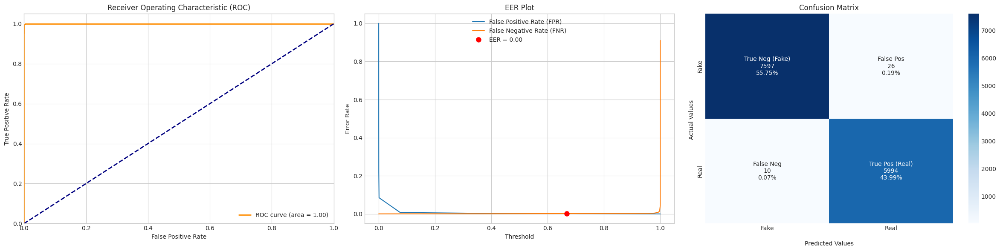

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
plt.style.use('seaborn-v0_8-whitegrid')

# 1. ROC Curve
roc_auc = roc_auc_score(y_true, y_scores)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Receiver Operating Characteristic (ROC)')
axes[0].legend(loc="lower right")

# 2. EER Plot
axes[1].plot(thresholds, fpr, label='False Positive Rate (FPR)')
axes[1].plot(thresholds, fnr, label='False Negative Rate (FNR)')
axes[1].plot(eer_threshold, EER, 'ro', ms=8, label=f'EER = {EER:.2f}')
axes[1].set_title('EER Plot')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Error Rate')
axes[1].legend()

# 3. Confusion Matrix
cf_matrix = confusion_matrix(y_true, y_preds)
group_names = ['True Neg (Fake)','False Pos','False Neg','True Pos (Real)']
group_counts = [f"{value:0.0f}" for value in cf_matrix.flatten()]
group_percentages = [f"{value:.2%}" for value in cf_matrix.flatten()/np.sum(cf_matrix)]
labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]
labels = np.asarray(labels).reshape(2,2)
sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues', ax=axes[2])
axes[2].set_title('Confusion Matrix');
axes[2].set_xlabel('\nPredicted Values')
axes[2].set_ylabel('Actual Values ');
axes[2].xaxis.set_ticklabels(['Fake','Real'])
axes[2].yaxis.set_ticklabels(['Fake','Real'])

plt.tight_layout()
plt.show()

### 7. Model Explainability with Grad-CAM

To understand *why* our model makes a certain prediction, we can use Gradient-weighted Class Activation Mapping (Grad-CAM). This technique produces a heatmap that highlights the regions in the input image that were most important for the model's decision.

First, we need to find a suitable target layer within the MambaVision model. The last block of the model is a good candidate. Let's print the model architecture to identify it.

In [45]:
# Print the model architecture to find the target layer
print(model)

MambaVision(
  (patch_embed): PatchEmbed(
    (proj): Identity()
    (conv_down): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=0.0001, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 196, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (4): BatchNorm2d(196, eps=0.0001, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
    )
  )
  (levels): ModuleList(
    (0): MambaVisionLayer(
      (blocks): ModuleList(
        (0): ConvBlock(
          (conv1): Conv2d(196, 196, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (norm1): BatchNorm2d(196, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (act1): GELU(approximate='tanh')
          (conv2): Conv2d(196, 196, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (norm2): BatchNorm2d(196, eps=1e-05, momentum=0.1, affine=True, tra

From the architecture printout, `model.layers[-1].norm` or `model.layers[-1].mixer` seems like a good target. We will use the final mixer layer in the last block: `model.layers[-1].mixer`.


### MambaVision and GradCAM.

Unlike it's predecessor VisionMamba (Vim), MambaVision is a hybrid architecture that adopts the same "patch and tokenize" strategy as Vision Transformers. The Mamba blocks process sequences of tokens that retain their spatial relationship to the original image patches. Therefore, we can apply Grad-CAM to MambaVision's layers by reshaping its token outputs, just as is done for standard Vision Transformers


--- Grad-CAM Explainability on Test Set Samples ---


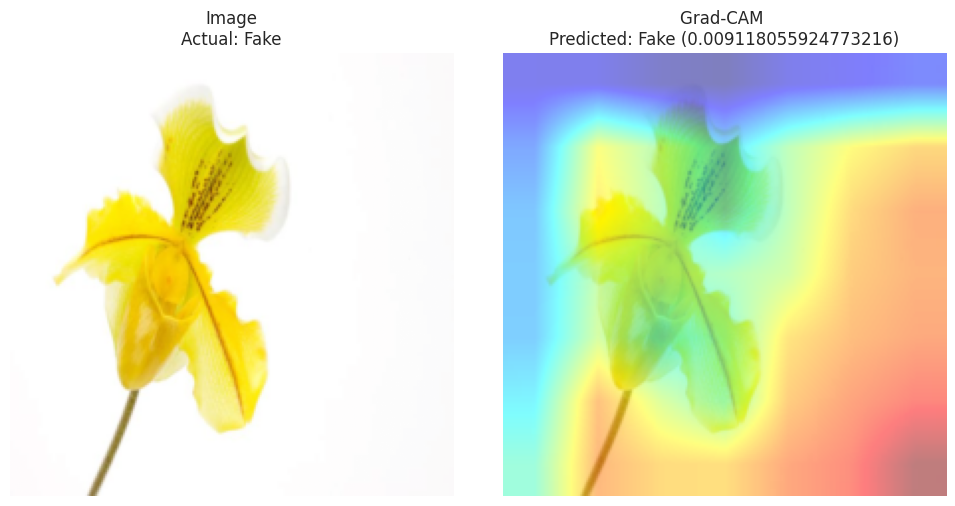

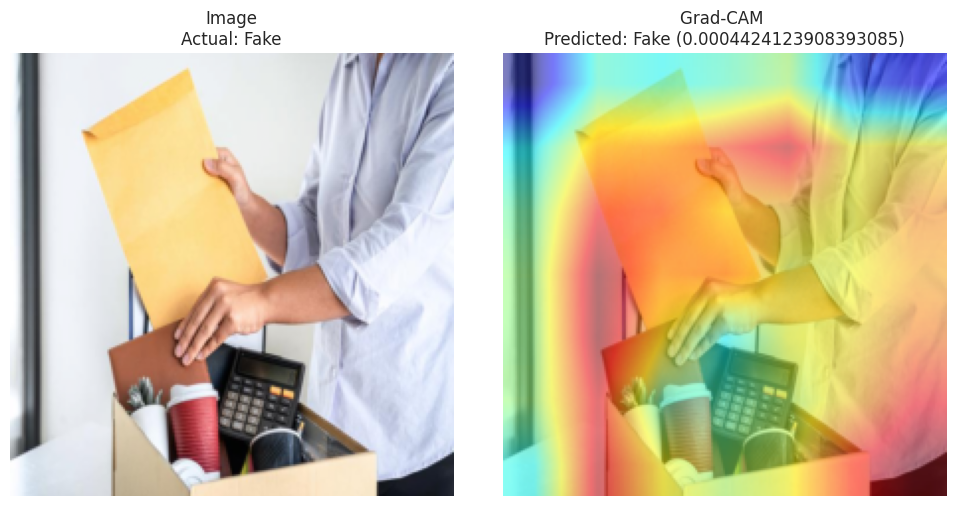

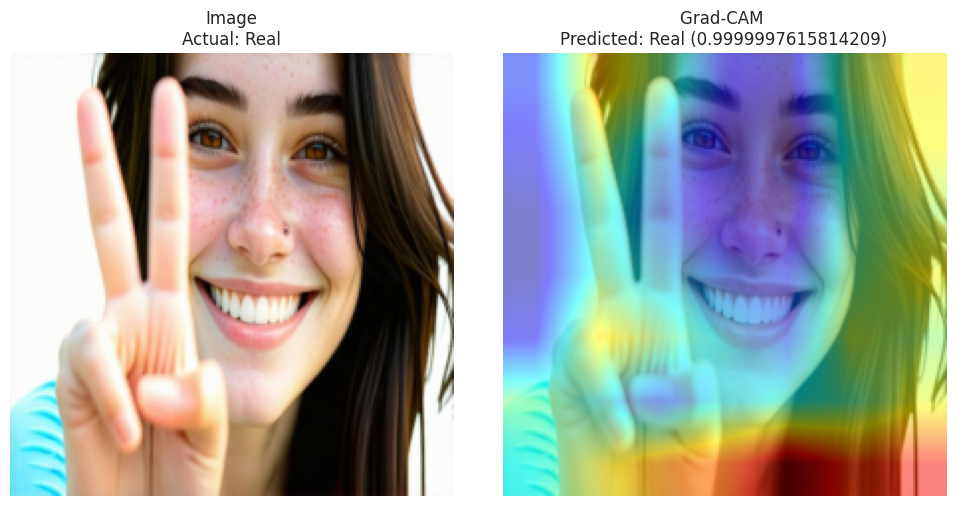

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# The MambaVision model from the library does not use a prepended [CLS] token.
# Its output is averaged across the patch dimension. So we reshape all tokens.
def reshape_transform_mambavision(tensor, height=7, width=7):
    # The MambaVision-T model outputs features of shape (batch, 49, 640) before the head
    # 49 tokens = 7x7 grid.
    result = tensor.reshape(tensor.size(0), height, width, tensor.size(2))
    result = result.permute(0, 3, 1, 2)
    return result

# Define the correct target layer. We target the final mixer in the last stage.
# The model architecture has 'levels', not 'layers'.
target_layers = [model.levels[-1].blocks[-1].mixer]

# Create a Grad-CAM instance
cam = GradCAM(model=model, target_layers=target_layers, reshape_transform=reshape_transform_mambavision)

# Denormalize image for visualization using the same stats as training
inv_normalize = transforms.Normalize(
    mean=[-m/s for m, s in zip(imagenet_mean, imagenet_std)],
    std=[1/s for s in imagenet_std]
)

def visualize_grad_cam(img_tensor, label):
    """Generates and displays a Grad-CAM visualization for a given image."""
    # Add batch dimension and send to device
    input_tensor = img_tensor.unsqueeze(0).to(DEVICE)
    
    # The model has a single output neuron for binary classification.
    # We must target this single output, which is at index 0.
    targets = [ClassifierOutputTarget(0)]
    
    # Generate CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]
    
    # Prepare image for display
    rgb_img = inv_normalize(img_tensor).permute(1, 2, 0).cpu().numpy()
    rgb_img = np.clip(rgb_img, 0, 1)
    
    # Overlay CAM
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    
    # Get model's prediction
    pred_score = torch.sigmoid(model(input_tensor)).item()
    pred_label = "Real" if pred_score > 0.5 else "Fake"
    actual_label = "Real" if label == 1 else "Fake"
    
    # Display
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(rgb_img)
    ax1.set_title(f"Image\nActual: {actual_label}")
    ax1.axis('off')
    
    ax2.imshow(visualization)
    ax2.set_title(f"Grad-CAM \nPredicted: {pred_label} ({pred_score})")
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

# Visualize a few examples from the test set for an unbiased view
print("\n--- Grad-CAM Explainability on Test Set Samples ---")
if len(test_dataset) > 60:
    indices_to_show = [8, 26, 58]
    for idx in indices_to_show:
        sample_img, sample_label = test_dataset[idx]
        visualize_grad_cam(sample_img, sample_label)
else:
    print("Test set is too small to show samples.")